# The liquidity ladder, the net liquidity position and the survival period

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (install the engine and open an artifact)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- read the contractual maturity ladder of a balance sheet and say why its gaps do not say when a bank runs out of liquidity;
- state the net liquidity position `NLP(t)` and the survival period, and reproduce both with the engine on the committed document of case C16;
- explain the cliff effect and why it is a diagnostic and not a limit;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C16 of Contraste: the balance sheet of the bank that failed on 2023-03-10, built from the FDIC call reports up to 2022-12-31 (public aggregates, licence class `mirror-allowed`). The aggregates are real, the **behaviour and the deposits are synthetic**: the case does not represent the bank and certifies no model.

- **File read:** `data/derived/C16/list-adverse.json`, the variant that runs the ECB LiST 2019 Adverse run-off over the six months after 2022-12-31 (125 relevant days).
- **Units:** money in USD thousands, days counted from 1 (day 1 is the first relevant day after the valuation date).
- The ladder keys used here are `outputs.contractual_ladder`, `outputs.path.ladder` (the daily series) and `outputs.path.survival`.

The next cell loads the document and prints which engine version baked it, next to the installed one.

In [2]:
# Load the committed LiST Adverse document of case C16 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
document = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
out = document["outputs"]

print("baked by riskvalidation", document["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("valuation date:", out["valuation_date"], "| currency:", out["currency"])
print(out["bank"]["notice"]["en"])

baked by riskvalidation 0.9.0 | installed 0.9.0
valuation date: 2022-12-31 | currency: USD
Real FDIC call-report aggregates used as public aggregates only, with synthetic behaviour and synthetic deposits: the case does not represent the bank and certifies no model.


## Method

The liquidity ladder of the European Central Bank's 2019 liquidity stress test (LiST) has four pieces, each a function of `riskvalidation.liquidity.ladder` (ECB, 2019, methodological note and results annex, section E.1 of the research dossier). We run them one by one on the committed document.

### Step 1: the contractual gaps

A contractual ladder puts every flow in the bucket of its contractual maturity. With the inflows $I_b$ and the outflows $O_b$ of bucket $b$, the gap and the cumulative gap are (the contractual maturity mismatch tool of the Basel Framework, SRP50):

$$\mathrm{gap}_b = I_b - O_b, \qquad \mathrm{cumulative\ gap}_b = \sum_{k \le b} \mathrm{gap}_k$$

The next cell reads the seven buckets of the document, calls `contractual_gaps` and compares the result with the committed gaps.

In [3]:
# The seven contractual buckets of the document, and the engine's gap and cumulative gap
from riskvalidation.liquidity.ladder import contractual_gaps

buckets = out["contractual_ladder"]["buckets"]
inflows = np.array([b["inflows"] for b in buckets])
outflows = np.array([b["outflows"] for b in buckets])
gap, cumulative_gap = contractual_gaps(inflows, outflows)

print(f"{'from day':>12s}{'to day':>14s}{'inflows':>12s}{'outflows':>12s}{'gap':>12s}{'cumulative':>14s}   (USD billions)")
for b, g, c in zip(buckets, gap, cumulative_gap):
    end = "-" if b["to_day"] is None else str(b["to_day"])
    print(f"{b['from_day']:12d}{end:>14s}{b['inflows'] / 1e6:12.2f}{b['outflows'] / 1e6:12.2f}{g / 1e6:12.2f}{c / 1e6:14.2f}")
print("same gap as the document:", bool(np.allclose(gap, [b["gap"] for b in buckets])))
print("same cumulative gap:", bool(np.allclose(cumulative_gap, [b["cumulative_gap"] for b in buckets])))

    from day        to day     inflows    outflows         gap    cumulative   (USD billions)
           0             1       92.90      174.48      -81.58        -81.58
           1             7       83.00        0.31       82.69          1.10
           7            30       94.27        1.20       93.07         94.18
          30            90      118.80        3.12      115.68        209.86
          90           180       80.07        3.87       76.20        286.06
         180           365       81.18        7.95       73.22        359.28
         365             -      128.55        0.01      128.54        487.82
same gap as the document: True
same cumulative gap: True


The first bucket, from day 0 to day 1, is negative by far: the demand deposits have no contractual maturity and sit in the first bucket, while the assets of the balance sheet mature later. Every later cumulative gap is positive. The contractual view says the bank is short only on the first day and then comfortable, which is exactly what a run does not respect.

### Step 2: the net liquidity position

The behavioural ladder replaces the contractual flows by stressed ones. With the counterbalancing capacity $\mathrm{CBC}(t)$ (the stock of unencumbered liquid assets after haircuts that can be turned into cash by day $t$) and the stressed outflows $O(s)$ and inflows $I(s)$ of day $s$ (ECB, 2019, definitions of the LiST):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \bigl(O(s) - I(s)\bigr)$$

The next cell reads the three daily series of the document (125 days), calls `net_liquidity_position` and compares it with the committed series.

In [4]:
# The daily CBC, outflows and inflows of the document, and the engine's NLP
from riskvalidation.liquidity.ladder import net_liquidity_position

ladder = out["path"]["ladder"]
cbc = np.array(ladder["cbc_total"])
daily_outflows = np.array(ladder["total_outflows"])
daily_inflows = np.array(ladder["total_inflows"])
nlp = net_liquidity_position(cbc, daily_outflows, daily_inflows)

print("days on the ladder:", len(nlp))
print("same NLP as the document:", bool(np.allclose(nlp, ladder["nlp"])))
for day in (1, 2, 3, 30, 61, 62, 125):
    print(f"day {day:3d} | CBC {cbc[day - 1] / 1e6:8.2f} | cumulative net outflow {(np.cumsum(daily_outflows - daily_inflows))[day - 1] / 1e6:8.2f} | NLP {nlp[day - 1] / 1e6:8.2f}")

days on the ladder: 125
same NLP as the document: True
day   1 | CBC    35.84 | cumulative net outflow    14.86 | NLP    20.98
day   2 | CBC    57.34 | cumulative net outflow    15.99 | NLP    41.35
day   3 | CBC    71.67 | cumulative net outflow    17.12 | NLP    54.55
day  30 | CBC    71.67 | cumulative net outflow    44.96 | NLP    26.71
day  61 | CBC    71.67 | cumulative net outflow    71.56 | NLP     0.11
day  62 | CBC    71.67 | cumulative net outflow    72.33 | NLP    -0.66
day 125 | CBC    71.67 | cumulative net outflow   112.64 | NLP   -40.97


The identity is visible in the table: the NLP of a day is the CBC of that day minus the cumulative net outflow. The CBC grows over the first three days (the monetisation schedule is a stated convention: 50%, 80% and 100% of the liquidity value of the assets on days 1, 2 and 3) and then stays flat, while the cumulative net outflow keeps rising by the stressed run-off of every day. Around day 62 the two lines cross.

### Step 3: the survival period

The survival period is the first day on which the NLP turns negative (ECB, 2019):

$$\mathrm{SP} = \min\{\, t : \mathrm{NLP}(t) < 0 \,\}$$

A zero NLP is not negative. A position that never turns negative has no survival day: the engine returns "survives the horizon" with the horizon, never a number. The next cell calls `survival_period` and `minimum_nlp` and compares them with the document.

In [5]:
# The survival period and the minimum NLP, from the engine, against the committed values
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

result = survival_period(nlp)
low, low_day = minimum_nlp(nlp)
committed = out["path"]["survival"]

print("survives the horizon:", result.survives, "| survival day:", result.day, "| horizon:", result.horizon)
print("committed survival day:", committed["day"], "| impact of the document:", document["impact"]["survival_days"]["value"])
print("minimum NLP (USD billions) and its day:", round(low / 1e6, 2), low_day)
print("same minimum as the document:", bool(np.isclose(low, out["path"]["minimum_nlp"]["value"])) and low_day == out["path"]["minimum_nlp"]["day"])

survives the horizon: False | survival day: 62 | horizon: 125
committed survival day: 62 | impact of the document: 62.0
minimum NLP (USD billions) and its day: -40.97 125
same minimum as the document: True


### Step 4: the cliff effect

The cliff effect compares the NLP on two days, a month and a month and a week after the start, as a share of total assets $\mathrm{TA}$ (ECB, 2019):

$$\mathrm{cliff} = \frac{\mathrm{NLP}(35) - \mathrm{NLP}(30)}{\mathrm{TA}}$$

It is a diagnostic of LCR window optimisation: a bank that arranges its flows so that the 30-day liquidity coverage ratio looks fine can still drop sharply a few days later. The LiST note does not say whether the days count calendar or relevant days; the engine takes them as the named parameter `cliff_days` and the document counts relevant days (a stated convention). The next cell calls `cliff_effect` with the total assets of the balance sheet.

In [6]:
# The cliff effect between day 30 and day 35 as a share of total assets, from the engine
from riskvalidation.liquidity.ladder import cliff_effect

total_assets = out["balance_sheet"]["total_assets"]
cliff = cliff_effect(nlp, total_assets, near=30, far=35)

print("total assets (USD billions):", round(total_assets / 1e6, 2))
print("NLP(30) = ", round(nlp[29] / 1e6, 3), "| NLP(35) = ", round(nlp[34] / 1e6, 3), "| difference:", round((nlp[34] - nlp[29]) / 1e6, 3))
print("cliff effect:", round(cliff, 6), "| committed:", round(out["path"]["cliff"]["value"], 6))
print("same as the document:", bool(np.isclose(cliff, out["path"]["cliff"]["value"])))

total assets (USD billions): 209.03
NLP(30) =  26.713 | NLP(35) =  22.063 | difference: -4.65
cliff effect: -0.022246 | committed: -0.022246
same as the document: True


The last cell draws the two views side by side. On the left, the cumulative contractual gap by bucket: negative on the first day and positive afterwards. On the right, the behavioural NLP in billions of USD with its survival day marked: the position stays positive for two months and then turns negative, and the drop between days 30 and 35 is the cliff.

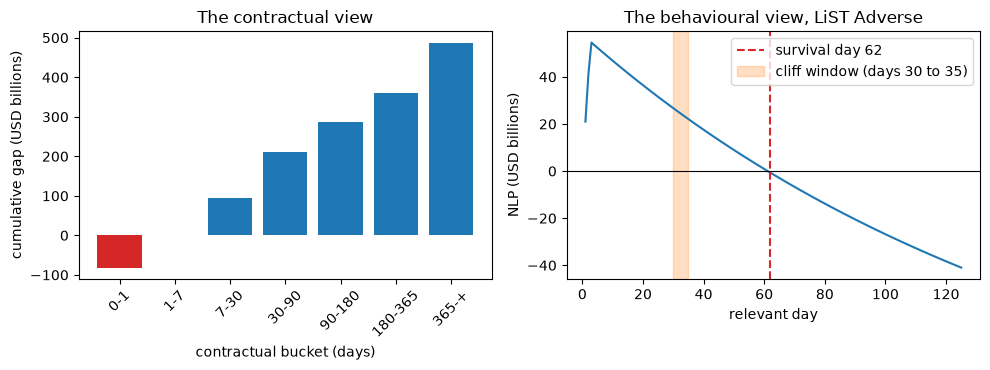

In [7]:
# Draw the cumulative contractual gap and the behavioural NLP with the survival day and the cliff window
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))

labels = [f"{b['from_day']}-{'+' if b['to_day'] is None else b['to_day']}" for b in buckets]
left.bar(range(len(buckets)), cumulative_gap / 1e6, color=["tab:red" if c < 0 else "tab:blue" for c in cumulative_gap])
left.set_xticks(range(len(buckets)))
left.set_xticklabels(labels, rotation=45)
left.set_xlabel("contractual bucket (days)")
left.set_ylabel("cumulative gap (USD billions)")
left.set_title("The contractual view")

days = np.arange(1, len(nlp) + 1)
right.plot(days, nlp / 1e6, color="tab:blue")
right.axhline(0, color="black", linewidth=0.8)
right.axvline(result.day, color="tab:red", linestyle="--", label=f"survival day {result.day}")
right.axvspan(30, 35, color="tab:orange", alpha=0.25, label="cliff window (days 30 to 35)")
right.set_xlabel("relevant day")
right.set_ylabel("NLP (USD billions)")
right.set_title("The behavioural view, LiST Adverse")
right.legend()
fig.tight_layout()
plt.show()

## Results

- **Contractual view.** The cumulative gap is negative only in the first bucket (-81.58 billion USD: the demand deposits, put at day 0 to 1) and positive in every later one, up to 487.82 billion in the last. The contractual view cannot tell when the bank runs short.
- **Net liquidity position.** The NLP starts at 20.98 billion on day 1 and rises to 54.55 on day 3 as the CBC is monetised (71.67 billion in total); then it falls with the accumulated run-off: 26.71 on day 30, 0.11 on day 61, -0.66 on day 62 and -40.97 on day 125, its minimum. The engine reproduces the whole committed series.
- **Survival period.** The survival period is day 62 of 125 under LiST Adverse, and the engine and the document agree. The margin is thin where it matters: on day 61 the NLP is only 0.11 billion above zero, so a small change in a run-off rate or in the CBC moves the day. The number is a property of the synthetic behaviour (the deposit mapping and the monetisation schedule are conventions), not a forecast for the bank.
- **Cliff effect.** The cliff effect is -0.0222: the NLP falls 4.65 billion between day 30 and day 35, 2.2% of the 209.03 billion of total assets. Engine and document agree. The document's own test row for the cliff grades it amber under its conventions (amber below -1%, red below -3%); the grade is a convention of the product, because the LiST note defines no limit.

What this notebook does not show: where the run-off rates and the CBC come from (notebooks 02 and 03), how scenarios are composed (notebook 04) or how the 30-day LCR relates to the survival period (notebook 05). The bank is real only in aggregate: the survival day is a property of the synthetic behaviour, not of the bank.

## Summary

- A contractual ladder gives gaps by maturity bucket; it cannot say when a bank with demand deposits runs out of cash.
- The net liquidity position is the CBC of the day less the cumulative stressed net outflow; the survival period is the first day it is negative, or "survives the horizon".
- The cliff effect is a diagnostic of the shape of the position, in shares of total assets, not a limit.
- Every number was recomputed with the engine from the daily series of the document and agrees with it.

**What to try next.** Change the window of the cliff (`near=20`, `far=25`) and see how the diagnostic moves; then continue with notebook 02, where the run-off rates behind the NLP are derived.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf